This is the model that came out to the research. 

# Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.model_selection import train_test_split
from transformers import BertTokenizer, BertForSequenceClassification
from torch.utils.data import Dataset, DataLoader
import torch
from tqdm import tqdm as notebook_tqdm
from sklearn.metrics import accuracy_score
from transformers import BertTokenizer, BertForSequenceClassification

from sklearn.metrics import confusion_matrix
import seaborn as sns
import matplotlib.pyplot as plt

# Bertje original model (copy)

## Data understanding

In [2]:
df_all = pd.read_csv("Data/sorted_words_labels.csv")

In [3]:
df_all.shape

(2459, 2)

In [4]:
df_all.value_counts('Label')

Label
Overige         2191
Water             97
Mobiliteit        81
Duurzaamheid      50
Armoede           40
Name: count, dtype: int64

In [5]:
df_all.info

<bound method DataFrame.info of                   Word    Label
0                water    Water
1     klimaatadaptatie    Water
2           watertoets    Water
3           drinkwater    Water
4         waterwinning    Water
...                ...      ...
2454               pas  Overige
2455      aanwezigheid  Overige
2456        onderzocht  Overige
2457            konden  Overige
2458        weerzijden  Overige

[2459 rows x 2 columns]>

In [6]:
df_all.describe()

,Word,Label
count,2459,2459
unique,2455,5
top,haven,Overige
freq,2,2191


## Data preparation

In [7]:
# Creating dataset that can be used to train for bertje for classification

class CustomDataset(Dataset):
    def __init__(self, data, tokenizer, max_len):
        self.data = data
        self.tokenizer = tokenizer
        self.max_len = max_len

        # Define a mapping from label strings to integers
        self.label_map = {"Water": 0, "Mobiliteit": 1, 'Duurzaamheid' : 2, "Armoede" : 3, "Overige" : 4}  # Update with your actual labels

    def __len__(self):
        return len(self.data)

    def __getitem__(self, index):
        word = str(self.data.iloc[index]['Word'])
        label = self.data.iloc[index]['Label']

        # Convert label string to integer index
        label_id = self.label_map.get(label, self.label_map["Overige"])

        encoding = self.tokenizer.encode_plus(
            word,
            add_special_tokens=True,
            max_length=self.max_len,
            return_token_type_ids=False,
            pad_to_max_length=True,
            return_attention_mask=True,
            return_tensors='pt',
            truncation=True
        )

        return {
            'word': word,
            'input_ids': encoding['input_ids'].flatten(),
            'attention_mask': encoding['attention_mask'].flatten(),
            'label': torch.tensor(label_id, dtype=torch.long)
        }



In [8]:
# Split data into train and validation sets
train_data, val_data = train_test_split(df_all, test_size=0.2, random_state=42)

# Load BERT tokenizer
tokenizer = BertTokenizer.from_pretrained("wietsedv/bert-base-dutch-cased")

# Define constants
MAX_LEN = 32
BATCH_SIZE = 8

# Create datasets and data loaders
train_dataset = CustomDataset(train_data, tokenizer, MAX_LEN)
val_dataset = CustomDataset(val_data, tokenizer, MAX_LEN)

train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False)

## Modeling

In [9]:

# Load pre-trained BERT model
model = BertForSequenceClassification.from_pretrained("wietsedv/bert-base-dutch-cased", num_labels=len(train_dataset.label_map))

# Fine-tune BERT model
device = torch.device('cuda') if torch.cuda.is_available() else torch.device('cpu')
model.to(device)
model.train()
optim = torch.optim.AdamW(model.parameters(), lr=5e-5)

# 20 epocs
for epoch in range(40):  # Adjust number of epochs as needed
    for batch in notebook_tqdm(train_loader):
        optim.zero_grad()
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)
        outputs = model(input_ids, attention_mask=attention_mask, labels=labels)
        loss = outputs.loss
        loss.backward()
        optim.step()

# Evaluation loop on validation dataset
model.eval()
val_preds = []
val_labels = []
val_words = []
for batch in val_loader:
    with torch.no_grad():
        input_ids = batch['input_ids'].to(device)
        attention_mask = batch['attention_mask'].to(device)
        labels = batch['label'].to(device)

        outputs = model(input_ids, attention_mask=attention_mask)
        logits = outputs.logits

        _, preds = torch.max(logits, dim=1)

        val_preds.extend(preds.cpu().numpy())
        val_labels.extend(labels.cpu().numpy())
        val_words.extend(batch['word'])

# Calculate accuracy
accuracy = accuracy_score(val_labels, val_preds)
print(f"Accuracy: {accuracy:.4f}")

# Print words along with true and predicted labels
print("Word\t\tTrue Label\tPredicted Label")
print("="*40)
for word, true_label, pred_label in zip(val_words, val_labels, val_preds):
    print(f"{word}\t\t{true_label}\t\t{pred_label}")


Some weights of BertForSequenceClassification were not initialized from the model checkpoint at wietsedv/bert-base-dutch-cased and are newly initialized: ['bert.pooler.dense.bias', 'bert.pooler.dense.weight', 'classifier.bias', 'classifier.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.
  0%|                                                                                          | 0/246 [00:00<?, ?it/s]C:\Users\naomi\anaconda3\Lib\site-packages\transformers\tokenization_utils_base.py:2699: FutureWarning: The `pad_to_max_length` argument is deprecated and will be removed in a future version, use `padding=True` or `padding='longest'` to pad to the longest sequence in the batch, or use `padding='max_length'` to pad to a max length. In this case, you can give a specific length with `max_length` (e.g. `max_length=45`) or leave max_length to None to pad to the maximal input size of the model (e.g. 512 for Bert).
  warni

Accuracy: 0.9390
Word		True Label	Predicted Label
unieke		4		4
verwoest		4		4
dertig		4		4
combineert		4		4
beschermingsbewind		3		4
ontwikkelde		4		4
stomp		4		4
teitswaarde		4		4
beschermingsbewind		3		4
ruimte		4		4
trekpleisters		4		4
klaslokalen		4		4
gevolg		4		4
genoemd		4		4
ieder		4		4
participatieavondonderzoek		4		4
stukken		4		4
participatieproces		4		4
volkswijken		4		4
beneden		4		4
erachter		4		4
nijverheid		4		4
impressies		4		4
kwaliteitsimpuls		4		4
schuldenproblematiek		3		3
grootte		4		4
architecten		4		4
rijksarchief		4		4
printer		4		4
contexthet		4		4
hectare		4		4
eb		0		4
dankt		4		4
vaststelling		4		4
milieuvriendelijk		2		2
stedelijk		4		4
agenda		4		4
speelplekken		4		4
mid		4		4
zomer		4		4
wonen		4		4
gebiedsontwikkeling		4		4
maximaal		4		4
waterzuivering		0		0
verontreinigingen		1		4
dankbaar		4		4
stapsgewijs		4		4
voormalig		4		4
aansluit		4		4
inmiddels		4		4
afspraken		4		4
bestaat		4		4
bebouwd		4		4
komen		4		4
volop		4		4
cafes		4		4
oorspronkelij

In [10]:
model.save_pretrained('Bertje_Water_Mobiliteit_Duurzaamheid_Armoede')

# Evaluation

## Load the test data

In [11]:
# dataset exist of words that are not in the dataset on which the model is trained

df_test = pd.read_csv("Data/sorted_mixed_validation.csv")

In [12]:
df_test.value_counts('Label')

Label
Water           30
Mobiliteit      29
Duurzaamheid    23
Overige         18
Armoede         17
Name: count, dtype: int64

## Functions

In [13]:
def predict_word_category(model_name_or_path, tokenizer, words, label_map):
    # Load the specified pretrained model
    model = BertForSequenceClassification.from_pretrained(model_name_or_path, num_labels=len(label_map), ignore_mismatched_sizes=True)
    model.eval()

    predicted_categories = []
    for word in words:
        # Preprocess the word
        encoded_input = tokenizer(word, padding=True, truncation=True, return_tensors="pt")
    
        # Pass the input through the model
        with torch.no_grad():
            output = model(**encoded_input)
    
        # Get predicted label
        predicted_label_idx = torch.argmax(output.logits).item()
    
        # Convert predicted index to label
        predicted_label = [label for label, idx in label_map.items() if idx == predicted_label_idx][0]
    
        predicted_categories.append(predicted_label)


    return predicted_categories



In [14]:
def evaluate_word_category_predictions(model_name_or_path, tokenizer, words, label_map, actual_labels):
    # Load the specified pretrained model
    model = BertForSequenceClassification.from_pretrained(model_name_or_path, num_labels=len(label_map), ignore_mismatched_sizes=True)
    model.eval()

    correct_predictions = 0
    total_predictions = 0

    for word, actual_label in zip(words, actual_labels):
        # Preprocess the word
        encoded_input = tokenizer(word, padding=True, truncation=True, return_tensors="pt")
    
        # Pass the input through the model
        with torch.no_grad():
            output = model(**encoded_input)
    
        # Get predicted label
        predicted_label_idx = torch.argmax(output.logits).item()
    
        # Convert predicted index to label
        predicted_label = [label for label, idx in label_map.items() if idx == predicted_label_idx][0]
    
        # Check if prediction is correct
        if predicted_label == actual_label:
            correct_predictions += 1

        total_predictions += 1

    accuracy = correct_predictions / total_predictions

    return accuracy



In [15]:
def plot_confusion_matrix(model_name_or_path, tokenizer, words, label_map, actual_labels):
    # Load the specified pretrained model
    model = BertForSequenceClassification.from_pretrained(model_name_or_path, num_labels=len(label_map), ignore_mismatched_sizes=True)
    model.eval()

    predicted_labels = []
    for word in words:
        # Preprocess the word
        encoded_input = tokenizer(word, padding=True, truncation=True, return_tensors="pt")
    
        # Pass the input through the model
        with torch.no_grad():
            output = model(**encoded_input)
    
        # Get predicted label
        predicted_label_idx = torch.argmax(output.logits).item()
    
        # Convert predicted index to label
        predicted_label = [label for label, idx in label_map.items() if idx == predicted_label_idx][0]
    
        predicted_labels.append(predicted_label)

    # Create confusion matrix
    cm = confusion_matrix(actual_labels, predicted_labels, labels=list(label_map.keys()))
    plt.figure(figsize=(10, 7))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=list(label_map.keys()), yticklabels=list(label_map.keys()))
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.title('Confusion Matrix')
    plt.show()

In [16]:
def print_incorrect_predictions(model_name_or_path, tokenizer, words, label_map, actual_labels):
    # Load the specified pretrained model
    model = BertForSequenceClassification.from_pretrained(model_name_or_path, num_labels=len(label_map), ignore_mismatched_sizes=True)
    model.eval()

    incorrect_predictions = []
    for word, actual_label in zip(words, actual_labels):
        # Preprocess the word
        encoded_input = tokenizer(word, padding=True, truncation=True, return_tensors="pt")
    
        # Pass the input through the model
        with torch.no_grad():
            output = model(**encoded_input)
    
        # Get predicted label
        predicted_label_idx = torch.argmax(output.logits).item()
    
        # Convert predicted index to label
        predicted_label = [label for label, idx in label_map.items() if idx == predicted_label_idx][0]
    
        # Check if prediction is correct
        if predicted_label != actual_label:
            incorrect_predictions.append((word, actual_label, predicted_label))

    return incorrect_predictions


## Evaluation

In [17]:
model_name_or_path = "Bertje_Water_Mobiliteit_Duurzaamheid_Armoede"  

In [ ]:
words_to_test_val = df_test['Word'].tolist()
actual_labels_val = df_test['Label'].tolist()

# Testing of random words

In [18]:
# Random word for testing
random_words_to_test = ["fiets", "auto", "huis","koffie","zand","banaan","water","overstroming","regen","bodem","energie","armoede","schuld","bijstand"]

In [19]:
# Predict the random words
predicted_categories = predict_word_category(model_name_or_path, tokenizer, random_words_to_test, train_dataset.label_map)
for word, category in zip(random_words_to_test, predicted_categories):
    print(f"The predicted category for the word '{word}' using the model '{model_name_or_path}' is: {category}")


The predicted category for the word 'fiets' using the model 'Bertje_Water_Mobiliteit_Duurzaamheid_Armoede' is: Mobiliteit
The predicted category for the word 'auto' using the model 'Bertje_Water_Mobiliteit_Duurzaamheid_Armoede' is: Mobiliteit
The predicted category for the word 'huis' using the model 'Bertje_Water_Mobiliteit_Duurzaamheid_Armoede' is: Overige
The predicted category for the word 'koffie' using the model 'Bertje_Water_Mobiliteit_Duurzaamheid_Armoede' is: Overige
The predicted category for the word 'zand' using the model 'Bertje_Water_Mobiliteit_Duurzaamheid_Armoede' is: Overige
The predicted category for the word 'banaan' using the model 'Bertje_Water_Mobiliteit_Duurzaamheid_Armoede' is: Overige
The predicted category for the word 'water' using the model 'Bertje_Water_Mobiliteit_Duurzaamheid_Armoede' is: Water
The predicted category for the word 'overstroming' using the model 'Bertje_Water_Mobiliteit_Duurzaamheid_Armoede' is: Water
The predicted category for the word 'reg

# Accuracy on a val_dataset

In [20]:
# Accuray on for the test dataset
model_name_or_path = "Bertje_Water_Mobiliteit_Duurzaamheid_Armoede"  # Example pretrained model
accuracy = evaluate_word_category_predictions(model_name_or_path, tokenizer, words_to_test_val, train_dataset.label_map, actual_labels_val)
print(f"Accuracy: {accuracy * 100:.2f}%")

Accuracy: 86.32%


# Confusion matrix

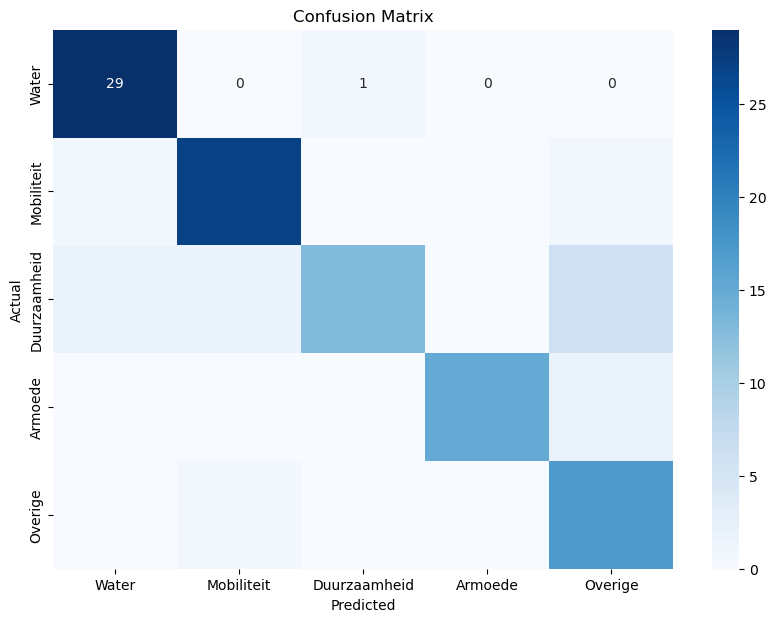

In [21]:
# Confusion matrix
plot_confusion_matrix(model_name_or_path, tokenizer, words_to_test_val, train_dataset.label_map, actual_labels_val)

##### Source of Bertje

@misc{devries2019bertje, <br>
	title = {{BERTje}: {A} {Dutch} {BERT} {Model}}, <br>
	shorttitle = {{BERTje}}, <br>
	author = {de Vries, Wietse  and  van Cranenburgh, Andreas  and  Bisazza, Arianna  and  Caselli, Tommaso  and  Noord, Gertjan van  and  Nissim, <br> Malvina}, <br>
	year = {2019}, <br>
	month = dec, <br>
	howpublished = {arXiv:1912.09582}, <br>
	url = {http://arxiv.org/abs/1912.09582}, <br>
}